# 01 · Volume patterns

**Data:** **[REAL]** the 2023 ticket export: 2,330 tickets created 2023-01-02 to
2023-12-30 (snapshot 2024-01-04 05:39), 8 named agents. No synthetic data is
used in this notebook.

*Part of the Support SLA & Capacity Review (full story: `reports/report.html`). Inputs are rebuilt by
`python run.py`; this notebook re-runs top to bottom with `make notebooks`.*

In [1]:
import json, pandas as pd, plotly.io as pio
pio.renderers.default = "notebook_connected+png"     # interactive in HTML export, static PNG fallback for GitHub
pio.renderers["png"].width, pio.renderers["png"].height = 1000, None
from support_ops import charts as C
from support_ops.data import load_processed, load_tickets
from support_ops.config import load_config, REPO_ROOT
kn = json.load(open(REPO_ROOT / "reports" / "key_numbers.json"))
cfg = load_config()

# --- also used in this notebook ----------------------------------------------
import numpy as np
from scipy import stats
from support_ops import kpis, rca, synth
from support_ops.sql import connect, run_sql_file
goal, aged_days = cfg["sla"]["goal_attainment"], cfg["sla"]["aged_backlog_days"]
pd.set_option("display.max_colwidth", 120)

## TL;DR

- **Volume did not grow.** **[REAL]** H2 had 1,149 tickets against 1,181 in H1
  (-2.7%). Months ranged from 159 to
  224 tickets (6.42 per calendar day on average), and
  the month-to-month variation is no larger than chance once each month's weekdays and weekend days are allowed for.
- **The mix did not shift.** **[REAL]** Email 53.0%, chat 36.5% and
  phone 10.6% of tickets over the year, with no trend by month, quarter or half; topic shares
  were stable too. A mix shift cannot explain the SLA decline: in the formal test (notebook 03), channel mix
  accounts for -0.28 of the
  -12.9-point fall in resolution SLA from Q1 to Q4.
- **Weekday-heavy, flat within the day.** **[REAL]** 7.67 tickets per weekday against
  3.45 per weekend day (weekends get 44.8% of the weekday
  volume). There is no business-hours peak: night hours carry as many tickets as office hours. That is unusual
  for a European B2B desk, so we treat the hourly shape as a data limitation.
- **Weekend work is bigger than weekend arrivals suggest.** **[REAL]** Resolutions per weekend day run at
  80.5% of the weekday level, against 44.8% for new
  tickets. Planning weekend cover on new-ticket counts alone would understate weekend work (indicative only: the
  export's resolution clocks ignore the calendar).
- **Demand is spread out.** **[REAL]** The top 20% of topics (2 of 7) hold
  49.6% of tickets, and the top 5 of 24
  topic × product combinations hold 44.5%. The largest topic,
  Product setup, is 27.0%. No single fix removes most of the volume.

In [2]:
# Every number in the TL;DR above, read from reports/key_numbers.json
tldr = {
    'Tickets H1': f"{kn['volume_h1']:,}",
    'Tickets H2': f"{kn['volume_h2']:,}",
    'Change H2 vs H1': f"{kn['volume_change_h2_vs_h1']:+.1%}",
    'Monthly tickets, lowest month': f"{kn['volume_monthly_min']}",
    'Monthly tickets, highest month': f"{kn['volume_monthly_max']}",
    'Tickets per calendar day': f"{kn['real_tickets_per_day']:.2f}",
    'Channel share: email': f"{kn['channel_share_email']:.1%}",
    'Channel share: chat': f"{kn['channel_share_chat']:.1%}",
    'Channel share: phone': f"{kn['channel_share_phone']:.1%}",
    'Q1->Q4 resolution SLA change from channel mix (pts)': f"{kn['rca_mix_effect_q1_q4_channel_pp']:+.2f}",
    'Q1->Q4 resolution SLA change in total (pts)': f"{kn['rca_mix_effect_q1_q4_channel_pp'] + kn['rca_rate_effect_q1_q4_channel_pp']:+.1f}",
    'Tickets per weekday': f"{kn['real_weekday_tickets_per_day']:.2f}",
    'Tickets per weekend day': f"{kn['real_weekend_tickets_per_day']:.2f}",
    'Weekend arrivals vs weekday': f"{kn['weekend_to_weekday_volume']:.1%}",
    'Weekend resolutions vs weekday': f"{kn['weekend_to_weekday_resolutions']:.1%}",
    'Top 20% of topics: count': f"{kn['pareto_top20pct_topics_n']} of 7",
    'Top 20% of topics: share of tickets': f"{kn['pareto_top20pct_topics_share']:.1%}",
    'Top 20% of topic x product: count': f"{kn['pareto_top20pct_combos_n']} of {kn['pareto_combos_total']}",
    'Top 20% of topic x product: share': f"{kn['pareto_top20pct_combos_share']:.1%}",
    'Largest topic': kn['top_topic'],
    'Largest topic: share': f"{kn['top_topic_share']:.1%}",
}
for label, value in tldr.items():
    print(f"{label:<54}{value}")

Tickets H1                                            1,181
Tickets H2                                            1,149
Change H2 vs H1                                       -2.7%
Monthly tickets, lowest month                         159
Monthly tickets, highest month                        224
Tickets per calendar day                              6.42
Channel share: email                                  53.0%
Channel share: chat                                   36.5%
Channel share: phone                                  10.6%
Q1->Q4 resolution SLA change from channel mix (pts)   -0.28
Q1->Q4 resolution SLA change in total (pts)           -12.9
Tickets per weekday                                   7.67
Tickets per weekend day                               3.45
Weekend arrivals vs weekday                           44.8%
Weekend resolutions vs weekday                        80.5%
Top 20% of topics: count                              2 of 7
Top 20% of topics: share of tickets           

## Question

The Support Director asked: *"SLA attainment is falling and the team says we're short-staffed … did volume go up,
or did efficiency go down?"* This notebook answers the volume half - **Q2** in `docs/01_request_and_scope.md`:

> Did ticket volume, or the mix of channels and topics, change enough to explain the SLA decline?
> (The mix matters because SLA targets differ by channel.)

It also records two inputs for later notebooks: **when** tickets arrive (weekday × hour; used for staffing in
notebook 04) and **what** they are about (topic concentration; used for automation sizing in notebook 05).

## Data

All tables are **[REAL]** and are rebuilt from the export by `python run.py`:

| table | built by | one row per |
|---|---|---|
| `fct_tickets` | `sql/00_fct_tickets.sql` | ticket (cleaned; SLA recomputed from timestamps) |
| `kpi_monthly` | `sql/01_kpi_monthly.sql` | month the ticket was created |
| `kpi_volume_heatmap` | `sql/06_volume_heatmap.sql` | weekday × hour of day (168 rows) |
| `kpi_topic_pareto` | `sql/07_topic_pareto.sql` | topic, and topic × product group |
| `kpi_channel_mix` | `support_ops.pipeline` (pandas group-by of `fct_tickets`) | month × channel |
| `dq_checks` | `sql/90_data_quality_checks.sql` | data-quality check |

In [3]:
fct = load_tickets()
monthly = load_processed("kpi_monthly")
heat = load_processed("kpi_volume_heatmap")
pareto = load_processed("kpi_topic_pareto")
mix = load_processed("kpi_channel_mix")
dq = load_processed("dq_checks")

print(f"Tickets created {fct.created_at.min():%Y-%m-%d} to {fct.created_at.max():%Y-%m-%d}, "
      f"snapshot {fct.snapshot_at.iloc[0]:%Y-%m-%d %H:%M}")
pd.Series({"fct_tickets": len(fct), "kpi_monthly": len(monthly), "kpi_volume_heatmap": len(heat),
           "kpi_topic_pareto": len(pareto), "kpi_channel_mix": len(mix), "dq_checks": len(dq)}, name="rows").to_frame()

Tickets created 2023-01-02 to 2023-12-30, snapshot 2024-01-04 05:39


,rows
fct_tickets,2330
kpi_monthly,12
kpi_volume_heatmap,168
kpi_topic_pareto,31
kpi_channel_mix,36
dq_checks,31


In [4]:
# Is the export the whole desk? Ticket IDs have gaps (data-quality check 5)
dq.loc[dq.check_id == 5, ["check_name", "observed", "action_taken"]]

,check_name,observed,action_taken
5,Share of IDs present in the ID range (min..max),0.78,INFO: 22% of IDs in range are absent - export may be a subset of all tickets


## Method

- **Tickets per calendar day, by month.** Months differ in length, so we compare tickets per calendar day. Each
  month carries a 95% Poisson interval: if tickets arrive at random at a steady rate, a month's count of *n*
  tickets moves by roughly ±2√*n* by chance alone. A month far outside its interval would signal real change.
- **Is the month-to-month variation more than chance?** A chi-square goodness-of-fit test compares each month's
  count with what a steady rate would give. The expected count allows for the calendar: every day is expected to
  get the 2023 average for its weekday, because weekends get less than half the weekday volume and months differ
  in how many weekend days they contain.
- **Weekday × hour heatmap.** Average tickets per week in each of the 168 weekday-hour slots: tickets in the slot
  divided by how many of that weekday the export covers (SQL below).
- **Pareto.** Topics, and topic × product group, ranked by volume with the cumulative share. An 80/20 pattern
  would mean the top 20% of categories hold about 80% of tickets.
- **Mix stability.** Monthly channel shares, plus chi-square tests of whether the channel or topic mix depends
  on the period. The formal test of whether a mix shift explains the SLA decline (shift-share decomposition) is
  in notebook 03.

In [5]:
def show_sql(name, start=None, end=None):
    """Print a file from sql/, or only the part from marker `start` up to marker `end`."""
    text = (REPO_ROOT / "sql" / name).read_text()
    i = text.index(start) if start else 0
    print(text[i:text.index(end, i) if end else None].rstrip())


show_sql("06_volume_heatmap.sql", start="WITH f AS")

WITH f AS (
    SELECT * FROM read_parquet(coalesce(getvariable('fct_tickets_path'), 'data/processed/fct_tickets.parquet'))
),
grid AS (
    SELECT d.dow, h.hour
    FROM range(1, 8) AS d(dow) CROSS JOIN range(0, 24) AS h(hour)
),
weekday_counts AS (   -- how many Mondays, Tuesdays, ... are in the export window
    SELECT isodow(d) AS dow, count(*) AS n_days
    FROM generate_series((SELECT min(created_date) FROM f), (SELECT max(created_date) FROM f), INTERVAL 1 DAY) AS t(d)
    GROUP BY 1
),
cnt AS (
    SELECT created_dow AS dow, created_hour AS hour,
           count(*) AS tickets,
           count_if(channel = 'Email') AS tickets_email,
           count_if(channel = 'Chat')  AS tickets_chat,
           count_if(channel = 'Phone') AS tickets_phone
    FROM f GROUP BY 1, 2
)
SELECT
    g.dow,
    CASE g.dow WHEN 1 THEN 'Mon' WHEN 2 THEN 'Tue' WHEN 3 THEN 'Wed' WHEN 4 THEN 'Thu'
               WHEN 5 THEN 'Fri' WHEN 6 THEN 'Sat' ELSE 'Sun' END     AS dow_name,
    g.hour,
    coalesce

In [6]:
# The cached tables are exactly what the SQL files produce today
for name, sql_file in [("kpi_monthly", "01_kpi_monthly.sql"), ("kpi_volume_heatmap", "06_volume_heatmap.sql"),
                       ("kpi_topic_pareto", "07_topic_pareto.sql")]:
    pd.testing.assert_frame_equal(run_sql_file(sql_file), load_processed(name), check_dtype=False)
    print(f"sql/{sql_file:<24} re-run == data/processed/{name}.parquet")

sql/01_kpi_monthly.sql       re-run == data/processed/kpi_monthly.parquet
sql/06_volume_heatmap.sql    re-run == data/processed/kpi_volume_heatmap.parquet
sql/07_topic_pareto.sql      re-run == data/processed/kpi_topic_pareto.parquet


## Results

### 1. Did volume grow?

In [7]:
halves = fct.groupby("created_half").size()
print(f"H1 {halves['H1']:,} tickets, H2 {halves['H2']:,} tickets ({halves['H2'] / halves['H1'] - 1:+.1%})")
monthly.set_index(monthly.created_month.dt.strftime("%b"))[["tickets"]].T

H1 1,181 tickets, H2 1,149 tickets (-2.7%)


created_month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
tickets,224,159,203,173,219,203,202,194,164,200,213,176


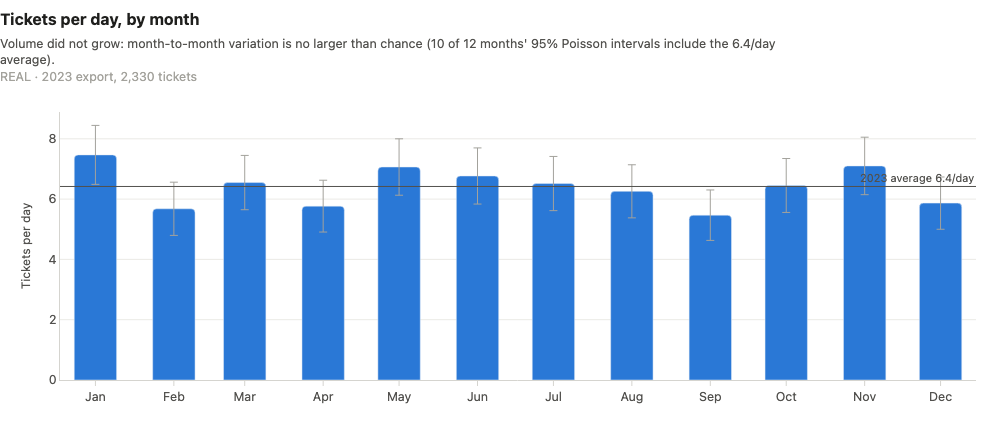

In [8]:
C.fig_monthly_volume(monthly)

**What this shows:** each bar is one month's tickets per calendar day, the whiskers are its 95% Poisson interval
and the line is the 2023 average. There is no growth: January is the busiest month and H2 is
2.7% below H1. September is the quietest month and its interval only just misses the
average line - about what chance produces somewhere in a 12-month year (tested next).

In [9]:
# Expected tickets per month if every day got its weekday's 2023 average (closed holidays excluded)
rate = synth.daily_rate_by_weekday(fct)                    # tickets per day, ISO weekday 1 = Mon
days = pd.Series(pd.date_range(fct.created_date.min(), fct.created_date.max()))
days = days[~days.isin(pd.to_datetime(synth.HOLIDAYS_2023))]
expected = days.dt.day_of_week.add(1).map(rate).groupby(days.dt.to_period("M")).sum().to_numpy()
observed = monthly["tickets"].to_numpy()
expected = expected * observed.sum() / expected.sum()
chi2, p_month = stats.chisquare(observed, expected)
print(f"Chi-square across 12 months: {chi2:.1f} on 11 degrees of freedom, p = {p_month:.2f}")
assert p_month > 0.05, "month-to-month variation is larger than chance - revisit the text"
pd.DataFrame({"observed": observed, "expected": expected.round(1),
              "z": ((observed - expected) / np.sqrt(expected)).round(2)},
             index=monthly.created_month.dt.strftime("%b"))

Chi-square across 12 months: 15.1 on 11 degrees of freedom, p = 0.18


,observed,expected,z
created_month,,,
Jan,224,196.4,1.97
Feb,159,181.0,-1.63
Mar,203,203.9,-0.06
Apr,173,187.9,-1.09
May,219,204.9,0.99
Jun,203,195.5,0.54
Jul,202,195.9,0.43
Aug,194,203.9,-0.69
Sep,164,191.5,-1.99


Allowing for each month's weekdays and weekend days, the variation between months is no larger than chance
(p = 0.18). January (+2.0 standard deviations) and September (-2.0) sit at the edge of
a 95% band; one or two months there is what chance alone produces in a year. **Volume did not grow, and the data
cannot distinguish any seasonal pattern from noise.**

### 2. When do tickets arrive?

In [10]:
weekday_rate = rate.rename(index=dict(enumerate(C.DAYS, 1))).round(2)
print("Tickets per day by weekday (closed holidays excluded):", weekday_rate.to_dict())
print(f"Weekday average {rate.loc[1:5].mean():.2f}, weekend average {rate.loc[6:7].mean():.2f} tickets per day")

by_hour = fct.groupby("created_hour").size()
print(f"Tickets by hour of day over the year: lowest {by_hour.min()} ({by_hour.idxmin():02d}:00), "
      f"highest {by_hour.max()} ({by_hour.idxmax():02d}:00); "
      f"share created 00:00-06:00: {fct.created_hour.lt(6).mean():.1%}")
p_dow_hour = stats.chi2_contingency(pd.crosstab(fct.created_dow, fct.created_hour))[1]
print(f"Same hourly profile on every weekday? chi-square p = {p_dow_hour:.2f}")

Tickets per day by weekday (closed holidays excluded): {'Mon': 8.04, 'Tue': 7.39, 'Wed': 8.44, 'Thu': 7.1, 'Fri': 7.38, 'Sat': 3.17, 'Sun': 3.72}
Weekday average 7.67, weekend average 3.45 tickets per day
Tickets by hour of day over the year: lowest 72 (14:00), highest 135 (15:00); share created 00:00-06:00: 26.3%
Same hourly profile on every weekday? chi-square p = 0.90


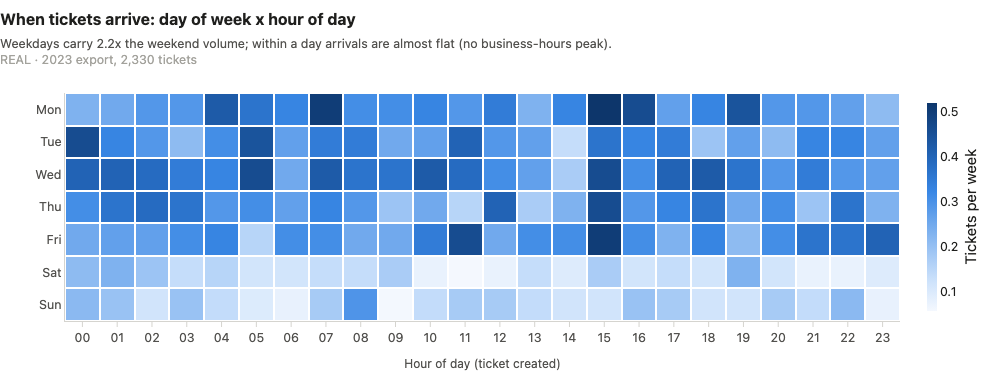

In [11]:
C.fig_volume_heatmap(heat)

**What this shows:** darker cells hold more tickets in that weekday-hour, averaged over the year. Weekdays
average 7.67 tickets a day against 3.45 at
weekends. Within a day the profile is flat: the six night hours (00:00-06:00) hold 26.3% of
tickets, a quarter of the day with a quarter of the volume, and the quietest and busiest hours
(14:00 and 15:00) are neighbours, which points to noise rather than a daily rhythm.
The hourly shape is the same on every weekday (p = 0.90). A flat 24-hour curve is unusual for a
European B2B desk and the export does not say what time zone it uses, so we do not staff to the hourly shape.

### 3. Weekend workload: arrivals vs resolutions

In [12]:
weekend = rca.weekend_workload(fct)
pd.DataFrame({"new tickets per day": weekend["created_per_day"],
              "tickets resolved per day": weekend["resolved_per_day"]}, index=C.DAYS).T

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
new tickets per day,7.88,7.25,8.44,7.1,7.38,3.17,3.65
tickets resolved per day,4.46,5.50,5.88,6.1,5.92,5.25,3.73


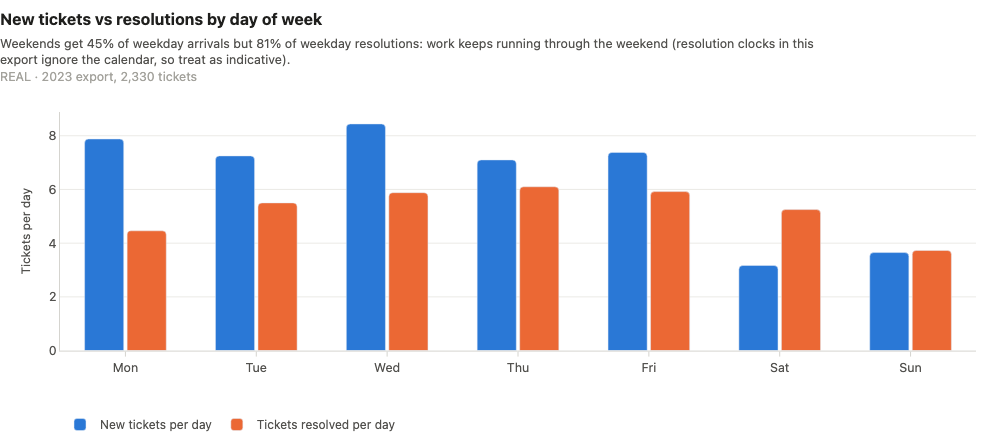

In [13]:
C.fig_weekday_workload(weekend)

**What this shows:** weekends get 44.8% of the weekday volume of new tickets but
80.5% of the weekday volume of resolutions: work that started in the week
keeps being closed at weekends. Resolution clocks in this export ignore the calendar, so treat this as indicative.
But if follow-ups really are done when they arise, planning weekend cover on new-ticket counts alone would
understate weekend work; the staffing model (notebook 04) plans on total workload for that reason.

### 4. What are tickets about? Topic Pareto

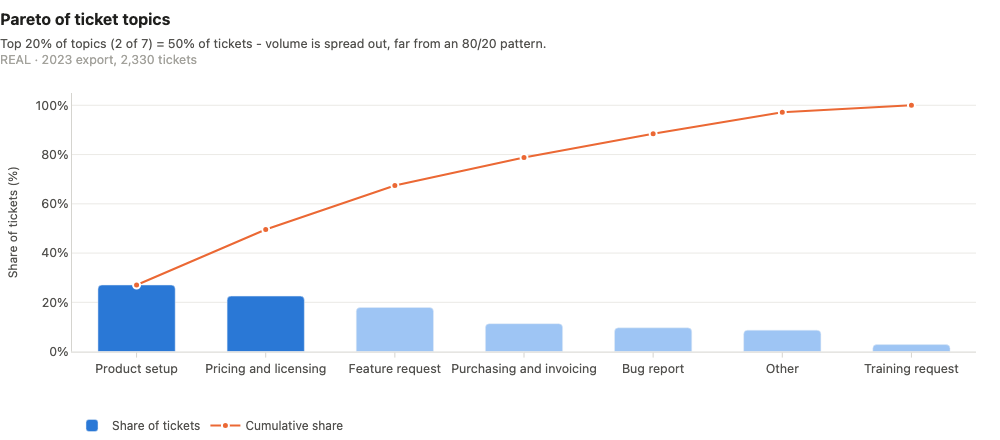

In [14]:
C.fig_topic_pareto(pareto, "topic")

**What this shows:** the two largest of seven topics hold 49.6% of tickets;
the largest, Product setup, is 27.0%. That is far from an 80/20 pattern: no single topic
fix removes most of the work.

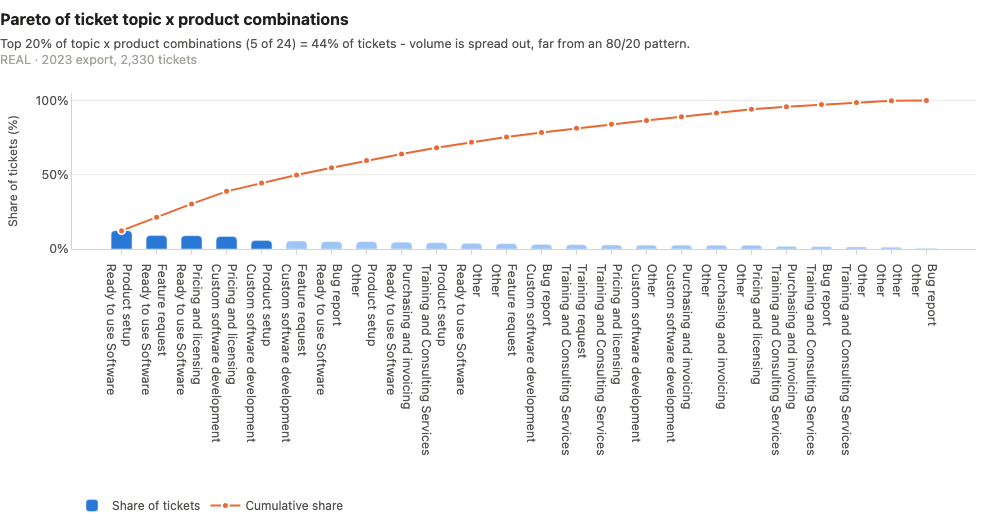

In [15]:
C.fig_topic_pareto(pareto, "topic x product")

**What this shows:** at topic × product-group level the top 5 of
24 combinations hold 44.5% of tickets, so concentration
does not sharpen at a finer grain. Automation candidates are therefore picked by volume together with how
informational or transactional a topic is (notebook 05), not by volume alone.

### 5. Did the channel or topic mix shift?

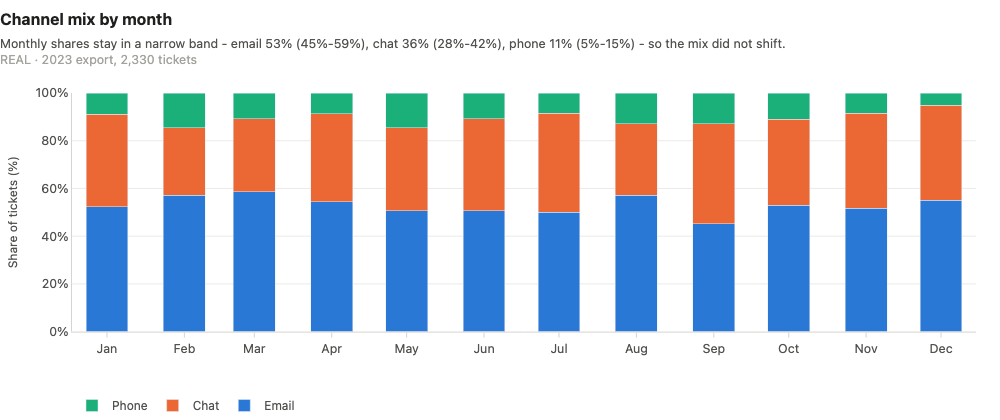

In [16]:
C.fig_channel_mix(mix)

**What this shows:** email is about half of every month's tickets, chat about a third and phone about a tenth.
Month-to-month wobble is visible (phone ranges from 5% to 15% of a month's tickets) but
there is no trend.

In [17]:
tests = []
for dim in ["channel", "topic"]:
    for period in ["created_month", "created_quarter", "created_half"]:
        chi2_mix, p_mix, dof, _ = stats.chi2_contingency(pd.crosstab(fct[period], fct[dim]))
        tests.append({"mix of": dim, "across": period.removeprefix("created_"), "chi2": round(chi2_mix, 1),
                      "dof": dof, "p_value": round(p_mix, 3)})
tests = pd.DataFrame(tests)
assert (tests.p_value > 0.05).all(), "a mix shift is larger than chance - revisit the text"
tests

,mix of,across,chi2,dof,p_value
0,channel,month,32.8,22,0.065
1,channel,quarter,8.0,6,0.239
2,channel,half,3.4,2,0.185
3,topic,month,59.9,66,0.689
4,topic,quarter,14.7,18,0.682
5,topic,half,2.3,6,0.886


In [18]:
# Channel shares, first vs second half of 2023
pd.crosstab(fct.created_half, fct.channel, normalize="index").round(3)

channel,Chat,Email,Phone
created_half,,,
H1,0.349,0.538,0.113
H2,0.381,0.521,0.097


None of the six tests finds a mix change larger than chance (all p > 0.05; the smallest, p = 0.065,
reflects month-to-month wobble without a trend). The small shifts that did occur explain
-0.28 points of the Q1 → Q4 fall in resolution SLA (shift-share, notebook
03). **The SLA decline did not come from more tickets or a different mix of tickets.**

### Cross-check against `reports/key_numbers.json`

Every headline number above, recomputed from the tickets in this notebook:

In [19]:
def crosscheck(recomputed):
    """Recomputed numbers must equal reports/key_numbers.json, to the rounding stored there."""
    rows = []
    for key, value in recomputed.items():
        stored, value = kn[key], (value.item() if hasattr(value, "item") else value)
        if isinstance(stored, (int, float)) and not isinstance(stored, bool):
            frac = repr(stored).partition(".")[2]                # 0.0271 -> 4 decimals, 202.0 -> 0
            decimals = 0 if frac in ("", "0") else len(frac)
            tol = max(0.5 * 10 ** -decimals, 1e-5 * abs(stored)) + 1e-9   # stored rounding or float noise
            ok = abs(float(value) - stored) <= tol
        else:
            ok = value == stored
        shown = round(value, 6) if isinstance(value, float) else value
        rows.append({"key": key, "key_numbers.json": stored, "recomputed here": shown, "match": ok})
    out = pd.DataFrame(rows, dtype=object)                       # keep ints as ints in the display
    bad = out[~out["match"].astype(bool)]
    assert bad.empty, bad.to_string()
    return out

In [20]:
pt = pareto[pareto.level == "topic"].sort_values("rank")
ptp = pareto[pareto.level == "topic x product"].sort_values("rank")
n_top, n_top_combo = int(np.ceil(0.2 * len(pt))), int(np.ceil(0.2 * len(ptp)))
days_in_window = (fct.created_date.max() - fct.created_date.min()).days + 1
crosscheck({
    "real_tickets": len(fct),
    "real_days_in_window": days_in_window,
    "real_tickets_per_day": len(fct) / days_in_window,
    "volume_h1": halves["H1"],
    "volume_h2": halves["H2"],
    "volume_change_h2_vs_h1": halves["H2"] / halves["H1"] - 1,
    "volume_monthly_min": monthly.tickets.min(),
    "volume_monthly_max": monthly.tickets.max(),
    "real_weekday_tickets_per_day": rate.loc[1:5].mean(),
    "real_weekend_tickets_per_day": rate.loc[6:7].mean(),
    "weekend_to_weekday_volume": weekend["created_weekend_to_weekday"],
    "weekend_to_weekday_resolutions": weekend["resolved_weekend_to_weekday"],
    "channel_share_email": fct.channel.eq("Email").mean(),
    "channel_share_chat": fct.channel.eq("Chat").mean(),
    "channel_share_phone": fct.channel.eq("Phone").mean(),
    "pareto_top20pct_topics_n": n_top,
    "pareto_top20pct_topics_share": pt.share.head(n_top).sum(),
    "pareto_combos_total": len(ptp),
    "pareto_top20pct_combos_n": n_top_combo,
    "pareto_top20pct_combos_share": ptp.share.head(n_top_combo).sum(),
    "top_topic": pt.category.iloc[0],
    "top_topic_share": pt.share.iloc[0],
})

,key,key_numbers.json,recomputed here,match
0,real_tickets,2330,2330,True
1,real_days_in_window,363,363,True
2,real_tickets_per_day,6.42,6.418733,True
3,volume_h1,1181,1181,True
4,volume_h2,1149,1149,True
5,volume_change_h2_vs_h1,-0.027096,-0.027096,True
6,volume_monthly_min,159,159,True
7,volume_monthly_max,224,224,True
8,real_weekday_tickets_per_day,7.67,7.67089,True
9,real_weekend_tickets_per_day,3.45,3.446538,True


## Limitations

- **One year of data.** Twelve months cannot separate a trend or seasonality from noise; next quarter's plan
  assumes the 2023 profile repeats.
- **The export may be a subset of the desk.** 22% of ticket IDs in the ID range are absent
  (data-quality check 5), so absolute volume may understate the real desk. Shares and trends are still usable if
  the missing IDs are random.
- **The hourly shape is not credible enough to staff to.** A flat 24-hour curve is unusual for European B2B
  customers, and the export does not document its time zone.
- **Weekend resolutions are indicative.** Resolution clocks in this export ignore weekends and resolution times
  are capped near 6 days, which may not reflect how the real desk works.
- **Tickets are not workload.** Volume counts contacts. Handle time is not in the export, so workload and
  staffing need an assumption (notebook 04).
- **Small cells.** At about 0.3 tickets an hour, most weekday-hour cells see 0-1 tickets a week; the heatmap
  shows the average shape, not a reliable rate for each slot.

## Recommendations

- **Support Director - do not build the headcount case on volume.** 2023 volume was flat (H2
  -2.7% vs H1), so the data does not support a request based on demand growth.
  *Measure:* weekly tickets vs the 2023 baseline. *Trigger to revisit:* volume sustained more than
  +25% above 2023, the growth the workload-matched roster absorbs in
  the **[SYNTHETIC]** planning scenario (notebook 04). *Risk:* demand can change with product launches; review
  monthly.
- **WFM / team leads - plan weekend cover on workload, not on new-ticket counts, after checking today's real
  roster.** Weekends get 44.8% of weekday arrivals but
  80.5% of weekday resolutions. *Measure:* weekend vs weekday response SLA
  and queue wait. *Risk:* the export's resolution clocks ignore the calendar, so weekend work may be overstated.
- **Self-service owner - expect several medium wins, not one big one.** The top two topics hold
  49.6% of tickets. Pilot self-service for pricing/licensing and invoicing, and
  route feature requests to a feedback portal. *Measure:* tickets per topic per week vs 2023. *Risk:* deflection
  rates are assumptions until piloted (notebook 05).
- **Ops Analytics - add this volume check to the monthly pack and confirm the timestamps' time zone.** A month
  outside its Poisson band is the early signal for a capacity review; a credible hourly profile is a precondition
  for hour-by-hour staffing. *Measure:* months outside the band; hourly profile from the source system. *Risk:*
  low - it is a reporting change.